# control de eventos con guardas: Métodos y evidencia

**Nivel:** 1 **Requisitos previos:** ninguno; Tema de entrada **Tiempo de lectura:** 15 minutos

**Pregunta:** ¿Qué acción admisible eligen la política de estados finitos protegida y el árbol de comportamiento para C01, y qué verifica la corrida nueva?

## Objetivos

Esta lección investiga la pregunta: ¿Qué acción admisible eligen la política de estados finitos protegida y el árbol de comportamiento para C01, y qué verifica la corrida nueva?

## Preparación

Las versiones siguientes están fijadas en `notebooks/requirements.txt` y también constan en los metadatos de este notebook; ```bash pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2 ```

In [1]:
# Importa la API publicada de políticas y las dependencias fijadas de gráficos y ejecución.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")
import sys
ROOT = Path('../../../').resolve()
sys.path.insert(0, str(ROOT))
checkpoint_dir = Path(os.environ.get('NEURAXIS_CHECKPOINTS', str(ROOT / 'models/checkpoints')))
planner_model = os.environ.get('NEURAXIS_NOTEBOOK_MODEL')
planner = OllamaPlanner(planner_model) if planner_model else None
sys.path.insert(0, str(ROOT / 'notebooks'))

reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Datos
El notebook lee artefactos comprometidos del producto. Propietario: Neuraxis. Repositorio: https://github.com/fsantibanezleal/CAOS_Neuraxis. Licencia: Apache-2.0. El JSON es un artefacto experimental propio y congelado; este notebook no redistribuye datos de benchmarks externos;

Este notebook lee `data/derived/index.json` y las trazas listadas. La ejecución usa un espacio aislado de caso Reflexmesh; Para métodos aprendidos, descarga los activos públicos exactos con `python -m reflexmesh.Cli fetch-models --destination models/checkpoints --version v0.01.000` y define `NEURAXIS_CHECKPOINTS` hacia esa carpeta; El manifiesto de publicación verifica los hashes. M09/M10 se leen desde trazas congeladas, salvo que `NEURAXIS_NOTEBOOK_MODEL` indique explícitamente un modelo Ollama local configurado;

Artefactos de esta lección:

- `data/derived/index.json` - `data/derived/episodes/M01-C01-nominal-40000 - `data/derived/episodes/M02-C01-nominal-40000 json`

## Método

Explica cómo una observación de evento se convierte en una elección acotada. La distinción central está entre ordenar un candidato registrado y otorgarle autoridad: el entorno admite solo la acción cuyos herramienta, argumentos y revisión del recurso satisfacen el contrato.

### Cantidad formal

M01 no utiliza un puntaje aprendido: elige el primer candidato cuya guarda satisface la revisión actual del recurso. M02 cambia la estructura del recorrido, no la regla de autoridad. Así, la traza permite inspeccionar por separado el orden de candidatos, el resultado de cada guarda y la poscondición verificada independientemente.

$$ a_t = \operatorname{primero}\{a \in C_t: g(a, o_t, r_t)=1\} $$

### Lectura del caso

C01 dirige un documento del espacio de trabajo mediante un efecto de archivo registrado. Revisa los candidatos y las guardas antes del archivo final: un destino correcto no basta si la revisión del recurso cambió después de observarlo. El oráculo comprueba la ruta y los bytes resultantes independientemente de la explicación de la política. M01 y M02 son deterministas, por lo que semillas nominales repetidas pueden reproducir la misma acción; es una propiedad de este caso diseñado, no evidencia de cobertura para cualquier sistema de archivos. El gráfico por variantes informa más que la única semilla ejecutada aquí porque expone las perturbaciones indexadas. Si las tasas de finalización coinciden, compara rechazos por estado obsoleto, número de acciones y latencia antes de declarar equivalencia. Un fallo debe seguir visible aunque el efecto de archivo se haya rechazado con seguridad.

### Interpretación de la evidencia

Interpreta con cautela un empate en C01. Los métodos pueden llegar al mismo destino mediante distinto orden de candidatos, evaluación de guardas o número de efectos, por lo que el archivo final oculta parte del control. El manifiesto identifica episodios canónicos; la repetición nueva de este notebook no se incorpora a esa matriz histórica. Conviene leer en orden: verificar bytes de entrada, inspeccionar la revisión observada del recurso, revisar candidatos, seguir la acción elegida y comprobar bytes de destino. Si el recurso cambia entre inspección y admisión, rechazar es un resultado correcto de seguridad aunque la tarea no termine. Así se separa una negativa segura de un fallo del controlador. El panel de latencia resume registros congelados por variante y semilla; debe leerse junto al éxito porque fallar rápido no es una mejora. Toda conclusión debe nombrar C01 y su contrato de archivo implementado, sin asumir lo mismo para instalación de paquetes, sistemas de archivos de red o editores concurrentes. Esos escenarios requieren sus propios trabajos, efectos y oráculos.

### Adapta el experimento

Para adaptar este ejercicio, crea un espacio desechable con un archivo enrutable, un distractor y una revisión modificada a propósito. Mantén inmutables los originales y registra hashes antes y después de la acción. Añade una segunda comprobación independiente de ruta y bytes de destino; no uses la traza de la política como oráculo. Una extensión útil cambia el orden de candidatos sin alterar el contrato de archivo y comprueba si la guarda sigue admitiendo solo la transición válida.

### control de eventos con guardas · nivel 1 | Verifica la auditoría y los bytes de cada traza antes de interpretar resultados.

In [2]:
# Load manifest-verified evidence and keep failures in every denominator.
import sys
sys.path.insert(0, str(ROOT / 'notebooks'))
from lesson_support import load_lesson_evidence
selected_methods = trace_methods = ['M01', 'M02']
sample_case, seed = 'C01', 40000
evidence = load_lesson_evidence(
    ROOT, topic='01-fast-event-control', methods=tuple(trace_methods),
    sample_case=sample_case, seed=seed,
    include_core=False, include_transfer=False,
)
index, audit = evidence['index'], evidence['audit']
records, case_records = evidence['records'], evidence['case_records']
print('Hash-verified records:', len(records), '| case variants:', len(case_records))


Hash-verified records: 2 | case variants: 12


### Inspeccionar una traza con guardas: control de eventos con guardas

C01 aísla decisiones rápidas con guardas: sigue la acción admitida y su poscondición antes de interpretar la rapidez.

Empieza por la revisión de la observación y la máscara de admisibilidad; luego sigue la acción hasta la poscondición verificada. Así separas tres preguntas que un indicador de éxito oculta: si la elección estaba permitida, si el evento elegido llegó a tiempo y si la tarea terminó. La traza canónica representa una condición diseñada; no estima con qué frecuencia ocurren eventos similares en software real.

### control de eventos con guardas · L1 | Construir la primera política ejecutable

En el nivel 1, construye M01 para control de eventos con guardas con la fábrica pública y conserva su contrato de observación antes de muestrear C01.


In [3]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = 'M01'
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Política principal:", primary_id)


Política principal: M01


### control de eventos con guardas · L1 | Ejecutar el método principal en el caso indicado

En el nivel 1 de control de eventos con guardas, el evaluador ejecuta M01 en C01 y deriva el éxito de la poscondición independiente, no de una traza reproducida.


In [4]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea principal:", primary_result["metrics"]["task_success"])


Éxito de tarea principal: 1


### control de eventos con guardas · L1 | Construir una política de comparación independiente

Para el nivel 1 de control de eventos con guardas, crea M02 como objeto nuevo para impedir que el estado recurrente de M01 contamine la comparación.


In [5]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = 'M02'
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Política de comparación:", secondary_id)


Política de comparación: M02


### control de eventos con guardas · L1 | Ejecutar la comparación bajo condiciones idénticas

Esta comparación de nivel 1 ejecuta M02 en el mismo C01, variante nominal y semilla, y ilustra comportamiento, no estima una tasa poblacional.


In [6]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea de comparación:", secondary_result["metrics"]["task_success"])


Éxito de tarea de comparación: 1


### control de eventos con guardas · L1 | Agregar los dos episodios ejecutados

En el nivel 1, el agregador resume dos episodios ejecutados de control de eventos con guardas, y las afirmaciones entre familias aún requieren el benchmark completo.


In [7]:
# Agrega los resultados ejecutados con el evaluador descriptivo del paquete.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Ejecuciones nuevas de políticas:", len(fresh_runs))
print("Éxitos de las ejecuciones nuevas:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Ejecuciones nuevas de políticas: 2
Éxitos de las ejecuciones nuevas: 2


Este panel de nivel 01 sobre acciones documentales con guardas agrega cada variante indexada después del resumen emparejado anterior.


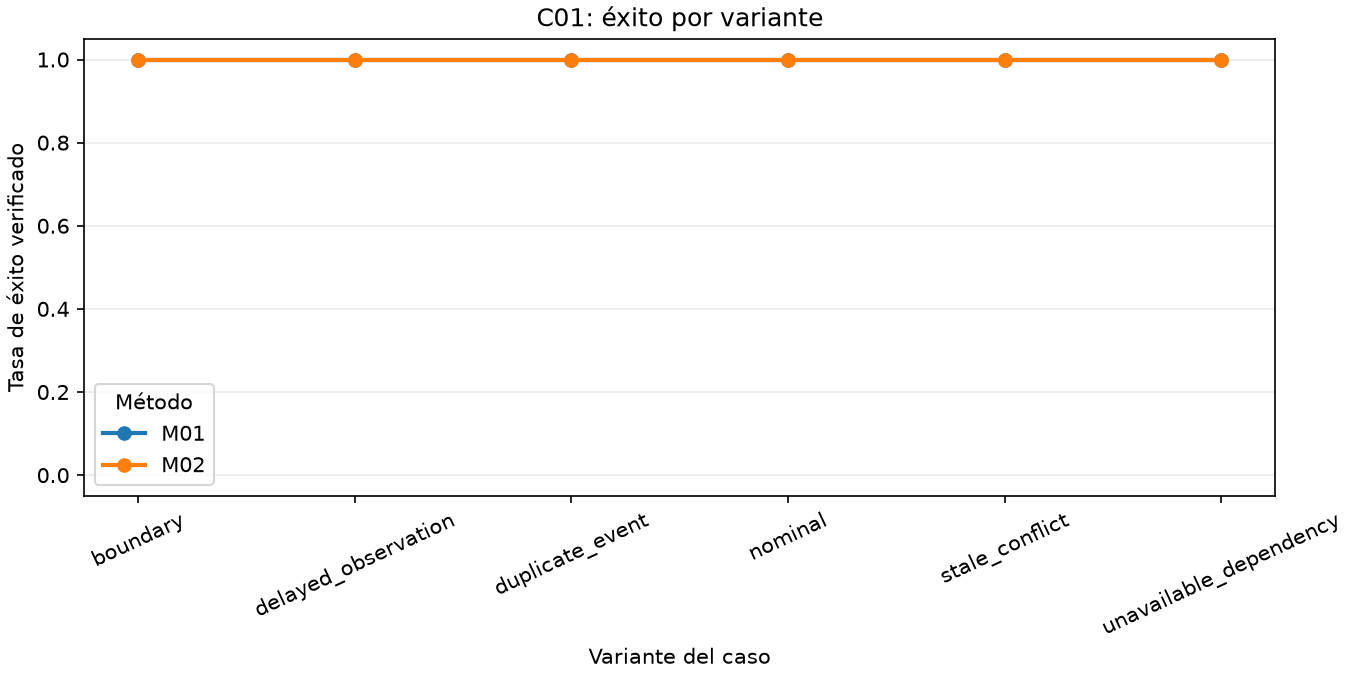

In [8]:
# Compare verified completion rates over every seed in each case variant.
methods_to_plot = selected_methods
variants = sorted({variant for _, variant in case_records})
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    rates = []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        rate = sum(bool(e['metrics']['task_success']) for e in episodes) / len(episodes) if episodes else float('nan')
        rates.append(rate)
    ax.plot(variants, rates, marker='o', linewidth=2, label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito verificado")
ax.set_xlabel("Variante del caso")
ax.set_title(sample_case + ": éxito por variante")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(title='Método' if True else 'Method')
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)




El gráfico 1, nivel 1, resume admisión por guardas y finalización verificada para C01 en el estudio de efectos de archivo registrados y carreras de revisiones obsoletas. Para el gráfico 1 de nivel 1, el denominador de efectos de archivo registrados y carreras de revisiones obsoletas contiene los episodios C01 cargados arriba y verificados con hashes del manifiesto; conserva los fallos. Los casos diseñados C01 del gráfico 1 de nivel 1 sobre efectos de archivo registrados y carreras de revisiones obsoletas no estiman incidentes reales ni rendimiento en software inédito. Lee el gráfico 1 de nivel 1 junto con la traza de efectos de archivo registrados y carreras de revisiones obsoletas y la poscondición verificada antes de atribuir una mejora al controlador.




El gráfico 1, nivel 1, resume admisión por guardas y finalización verificada para C01 en el estudio de efectos de archivo registrados y carreras de revisiones obsoletas. Para el gráfico 1 de nivel 1, el denominador de efectos de archivo registrados y carreras de revisiones obsoletas contiene los episodios C01 cargados arriba y verificados con hashes del manifiesto; conserva los fallos. Los casos diseñados C01 del gráfico 1 de nivel 1 sobre efectos de archivo registrados y carreras de revisiones obsoletas no estiman incidentes reales ni rendimiento en software inédito. Lee el gráfico 1 de nivel 1 junto con la traza de efectos de archivo registrados y carreras de revisiones obsoletas y la poscondición verificada antes de atribuir una mejora al controlador.

Para control de eventos con guardas, la figura de nivel 1 lee resultados de poscondición verificados por hash para M01 y M02 en las variantes indexadas de C01; La traza de guardas de C01 define cada éxito y mantiene los rechazos por revisión obsoleta en el denominador. Estas seis variantes de revisión y orden de eventos describen operaciones con guardas, no prevalencia en terreno.

### control de eventos con guardas · L1 | Latencia del controlador por variante

El panel de nivel 1 sobre control de eventos con guardas vincula el estrato archivado con la ejecución emparejada de arriba;


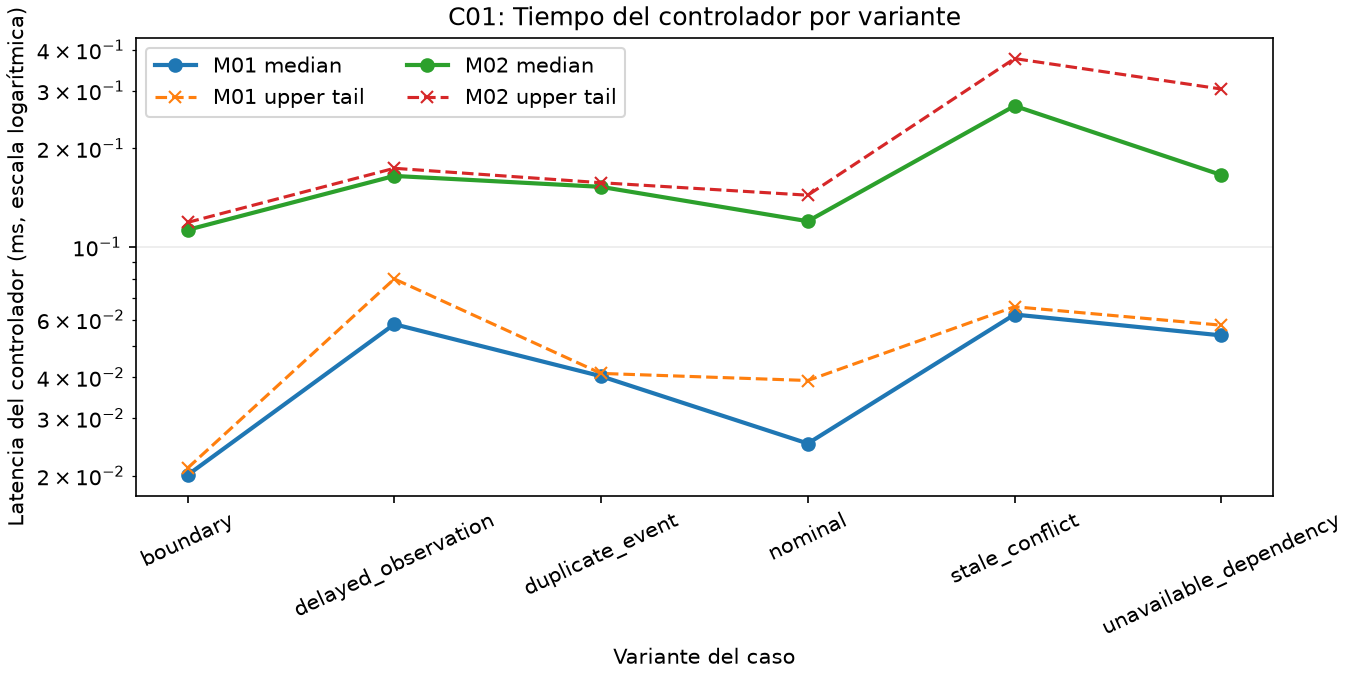

In [9]:
# Compare median and upper-tail controller time across all matched case variants.
variants = sorted({variant for _, variant in case_records})
methods_to_plot = selected_methods
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    p50, p95 = [], []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        values = sorted(float(e['metrics']['controller_ms']) for e in episodes)
        p50.append(values[(len(values) - 1) // 2] if values else float('nan'))
        p95.append(values[min(len(values) - 1, int(.95 * (len(values) - 1)))] if values else float('nan'))
    ax.plot(variants, p50, marker='o', linewidth=2, label=f'{method_id} median')
    ax.plot(variants, p95, marker='x', linestyle='--', label=f'{method_id} upper tail')
ax.set_yscale('log')
ax.set_ylabel('Latencia del controlador (ms, escala logarítmica)')
ax.set_xlabel('Variante del caso')
ax.set_title(sample_case + ': Tiempo del controlador por variante')
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(ncol=2)
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Excluyen espera del sistema y del usuario;

El gráfico 2, nivel 1, resume percentiles de decisión entre variantes de eventos para C01 en el estudio de efectos de archivo registrados y carreras de revisiones obsoletas. Para el gráfico 2 de nivel 1, el denominador de efectos de archivo registrados y carreras de revisiones obsoletas contiene los episodios C01 cargados arriba y verificados con hashes del manifiesto; conserva los fallos. Los casos diseñados C01 del gráfico 2 de nivel 1 sobre efectos de archivo registrados y carreras de revisiones obsoletas no estiman incidentes reales ni rendimiento en software inédito. Lee el gráfico 2 de nivel 1 junto con la traza de efectos de archivo registrados y carreras de revisiones obsoletas y la poscondición verificada antes de atribuir una mejora al controlador.


## Resultados

**Respuesta:** El ejemplo de control de eventos con guardas ejecuta 2 políticas, M01 y M02, en C01;

Dentro de esta ejecución de control de eventos con guardas (C01), esta repetición con el paquete comprueba una decisión protegida exacta sobre la misma observación congelada; En el ejercicio de una ejecución de control de eventos con guardas para C01, no demuestra transferencia general, un mecanismo biológico ni superioridad frente a un sistema desplegado y emparejado;

En el ejercicio de una ejecución de control de eventos con guardas para C01, este paso de autoría no compromete salidas generadas;

## Resumen

C01 valida una elección con guardas; afirmar rapidez general requiere estados y latencias medidos.




## Referencias
- [JEV](https://typesafe.ai/blog/introducing-system-one-models-and-jev) - [LEE](https://doi.org/10.1016/j.neuron.2013.11.028) - [DPT](https://aclanthology.org/2025.acl-long.206/)